# Step 1 — Loading and Combining Citi Bike Trip Data (2025)

## Objective

The Citi Bike dataset is published in monthly CSV files. In order to perform a comprehensive analysis of mobility patterns for the year 2025, all monthly datasets must first be combined into a single unified dataset.

This step ensures that the data exploration, cleaning, and spatial analysis are performed consistently across the entire year rather than on isolated monthly files.

## Purpose of This Step

The purpose of this step is to:

- Load all monthly CSV trip files for 2025
- Combine them into a single DataFrame
- Verify the structure and size of the dataset
- Ensure that all required variables are available before preprocessing

Without consolidating the files, it would not be possible to compute annual statistics, identify overall trends, or apply uniform cleaning procedures.

## Why This Approach Is Used

### 1. Automated File Detection
Instead of manually loading each month’s file, the notebook automatically retrieves all CSV files from the designated folder. This:
- Reduces human error
- Improves reproducibility
- Makes the workflow scalable

### 2. Adding a Source Identifier
A new column (`source_file`) is added to record the original file (month) from which each record originates. This is useful for:
- Debugging
- Checking month-specific inconsistencies
- Future monthly comparisons

### 3. Data Consolidation
All monthly datasets are concatenated into a single DataFrame using `pd.concat()`. This unified dataset enables:
- Annual summary statistics
- Global cleaning rules
- Consistent spatial and temporal analysis

## Expected Output

After running the loading cell, the following outputs are expected:

1. Number of CSV files detected
   - Should ideally match 12 (one per month for 2025).

2. Preview of detected filenames
   - Confirms correct directory selection.

3. Dataset dimensions (rows and columns)
   - Indicates total number of trips recorded in 2025.
   - Shows number of variables available for analysis.

4. Preview of first few rows
   - Confirms correct column names.
   - Ensures timestamps, coordinates, and station information appear valid.

In [22]:
import pandas as pd
import glob, os

DATA_DIR = r"citi_2025"   # <-- change this to your folder.

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
print("Number of CSV files found:", len(files))
print("First 3 files:", files[:3])

df_list = []
for f in files:
    tmp = pd.read_csv(f)
    tmp["source_file"] = os.path.basename(f)
    df_list.append(tmp)

df = pd.concat(df_list, ignore_index=True)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head(20)

Number of CSV files found: 12
First 3 files: ['citi_2025\\JC-202501-citibike-tripdata.csv', 'citi_2025\\JC-202502-citibike-tripdata.csv', 'citi_2025\\JC-202503-citibike-tripdata.csv']
Rows: 1002704
Columns: 14


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,source_file
0,880A0159BA5275FB,electric_bike,2025-01-16 17:50:49.136,2025-01-16 17:57:00.710,Hilltop,JC019,Pershing Field,JC024,40.731169,-74.057574,40.742677,-74.051789,member,JC-202501-citibike-tripdata.csv
1,1A5E1E274B2AF0AD,electric_bike,2025-01-31 06:10:41.818,2025-01-31 06:22:09.499,Hilltop,JC019,Jackson Square,JC063,40.731169,-74.057574,40.711130,-74.078900,member,JC-202501-citibike-tripdata.csv
2,EA9928D3C05B8377,classic_bike,2025-01-09 16:42:50.213,2025-01-09 17:04:12.870,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,JC-202501-citibike-tripdata.csv
3,3C42C367750B9292,electric_bike,2025-01-21 16:14:14.398,2025-01-21 16:37:10.458,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,JC-202501-citibike-tripdata.csv
4,94D3B0265A7BDE1F,classic_bike,2025-01-30 16:38:18.840,2025-01-30 17:04:08.166,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,JC-202501-citibike-tripdata.csv
5,9F58D1A2D274211B,electric_bike,2025-01-26 12:41:21.306,2025-01-26 12:50:06.079,Hilltop,JC019,Hoboken Terminal - Hudson St & Hudson Pl,HB101,40.731169,-74.057574,40.735938,-74.030305,member,JC-202501-citibike-tripdata.csv
6,06E081ED7FFC3B9A,electric_bike,2025-01-14 07:46:19.544,2025-01-14 07:54:25.887,Hilltop,JC019,Morris Canal,JC072,40.731169,-74.057574,40.712419,-74.038526,member,JC-202501-citibike-tripdata.csv
7,A2933F641B0B4756,electric_bike,2025-01-01 17:28:06.205,2025-01-01 17:35:36.233,Hilltop,JC019,Glenwood Ave,JC094,40.731169,-74.057574,40.727551,-74.071061,member,JC-202501-citibike-tripdata.csv
8,5A29AAD1161A2DC7,electric_bike,2025-01-13 12:33:51.980,2025-01-13 12:58:04.250,4 St & River St,HB611,Clinton St & Grand St,5303.06,40.740814,-74.027406,40.715595,-73.987030,casual,JC-202501-citibike-tripdata.csv
9,598F2567309571D5,electric_bike,2025-01-05 19:10:58.189,2025-01-05 19:18:46.106,Dixon Mills,JC076,Pershing Field,JC024,40.721630,-74.049968,40.742677,-74.051789,member,JC-202501-citibike-tripdata.csv


# Step 2 — Dataset Structure and Initial Exploration

## Objective

After successfully loading and combining all monthly Citi Bike trip files for 2025, the next step is to examine the dataset structure and understand the available variables.

Before cleaning or performing spatial analysis, it is essential to understand:

- What features are available
- The data types of each variable
- The scale of the dataset
- Whether there are missing or suspicious values

This step provides a structural overview of the dataset.

## Purpose of This Step

The purpose of this step is to:

- Identify all columns and their meanings
- Verify data types (e.g., datetime, numeric, categorical)
- Detect missing values
- Understand dataset size and completeness

Understanding the dataset structure ensures that preprocessing decisions (e.g., time conversion, coordinate filtering, duration calculation) are applied correctly.

## What the Code Will Show

The following commands are used:

- `df.info()` → Displays number of rows, column names, data types, and non-null counts.
- `df.describe()` → Provides summary statistics for numerical columns.
- `df.columns.tolist()` → Lists all variable names explicitly.

These outputs allow us to assess:

- Whether time columns need conversion
- Whether coordinate columns are numeric
- Whether there are missing station names or coordinates
- Whether numerical values appear within reasonable ranges

## Interpretation of Current Dataset

The combined 2025 dataset contains:

- 12 monthly files
- 1,002,704 trip records
- 14 variables

This indicates a large but manageable dataset suitable for annual mobility analysis.

The dataset likely includes the following types of variables:

- Trip identifiers (ride_id)
- Temporal variables (started_at, ended_at)
- Spatial variables (start_lat, start_lng, end_lat, end_lng)
- Station information (names and IDs)
- User category (member or casual)

Understanding the structure is critical because:

- Trip duration must be computed from datetime variables.
- Spatial analysis requires valid latitude and longitude columns.
- Temporal pattern analysis requires properly formatted time variables.
- Data cleaning rules depend on identifying invalid or missing records.

This step ensures that the dataset is ready for systematic cleaning and preprocessing in the next stage.

In [2]:

# 1️⃣ Display basic dataset structure
print("Dataset Shape (Rows, Columns):")
print(df.shape)
print("\n")

# 2️⃣ Display column names
print("Column Names:")
print(df.columns.tolist())
print("\n")

# 3️⃣ Display detailed information about dataset
print("Dataset Information:")
df.info()
print("\n")

# 4️⃣ Summary statistics for numerical columns
print("Summary Statistics (Numerical Columns):")
print(df.describe())
print("\n")

# 5️⃣ Check missing values in each column
print("Missing Values Per Column:")
print(df.isna().sum())

Dataset Shape (Rows, Columns):
(1002704, 14)


Column Names:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual', 'source_file']


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1002704 entries, 0 to 1002703
Data columns (total 14 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   ride_id             1002704 non-null  str    
 1   rideable_type       1002704 non-null  str    
 2   started_at          1002704 non-null  str    
 3   ended_at            1002704 non-null  str    
 4   start_station_name  1002701 non-null  str    
 5   start_station_id    1002701 non-null  str    
 6   end_station_name    999469 non-null   str    
 7   end_station_id      998307 non-null   str    
 8   start_lat           1002702 non-null  float64
 9   start_lng           1002702 non-n

# Step 3 — Data Quality Assessment and Cleaning

## Objective

Before performing spatial and temporal analysis, it is necessary to clean the dataset by removing incomplete, invalid, or unrealistic records.

The structural exploration revealed:

- Missing values in station identifiers and coordinates
- Datetime variables stored as strings
- Some missing destination coordinates
- Potential for unrealistic trip durations or speeds

Cleaning ensures that:

- Spatial geometries can be created correctly
- Trip duration calculations are accurate
- Statistical summaries are meaningful
- Routing and aggregation steps will not fail due to invalid data

## Identified Data Issues

1. **Missing Coordinates**
   - Missing `start_lat`, `start_lng`, `end_lat`, `end_lng`
   - Spatial analysis requires valid coordinates.

2. **Missing Station IDs**
   - Some missing `end_station_id`
   - These may correspond to incomplete trips.

3. **Datetime Columns Stored as Strings**
   - `started_at` and `ended_at` must be converted to datetime format.
   - Required for computing trip duration and temporal patterns.

## Cleaning Strategy

The following steps will be performed:

1. Convert time columns to datetime format.
2. Compute trip duration in seconds.
3. Remove trips with:
   - Missing coordinates
   - Duration ≤ 60 seconds (false starts)
   - Extremely long durations (> 4 hours) why i choose 4 hours as this is practical upper bound, allows long leisure rides, It excludes extreme anomalies.
   - 
4. Remove records with unrealistic geographic coordinates (outside NYC bounds).

This ensures a clean dataset suitable for spatial and mobility modelling analysis.

In [3]:
# Convert to datetime format
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

# Compute trip duration in seconds
df["trip_duration_sec"] = (
    df["ended_at"] - df["started_at"]
).dt.total_seconds()

print("Trip duration created.")

Trip duration created.


In [4]:
before_rows = len(df)

df = df.dropna(subset=["start_lat", "start_lng", "end_lat", "end_lng"])

after_rows = len(df)

print("Rows removed due to missing coordinates:", before_rows - after_rows)
print("Remaining rows:", after_rows)

Rows removed due to missing coordinates: 3446
Remaining rows: 999258


In [5]:
before_rows = len(df)

df = df[df["trip_duration_sec"] > 60]         # remove false starts
df = df[df["trip_duration_sec"] < 4 * 3600]   # remove > 4 hours

after_rows = len(df)

print("Rows removed due to unrealistic duration:", before_rows - after_rows)
print("Remaining rows:", after_rows)

Rows removed due to unrealistic duration: 1024
Remaining rows: 998234


In [6]:
before_rows = len(df)

df = df[
    (df["start_lat"].between(40.4, 41.0)) &
    (df["end_lat"].between(40.4, 41.0)) &
    (df["start_lng"].between(-74.5, -73.0)) &
    (df["end_lng"].between(-74.5, -73.0))
]

after_rows = len(df)

print("Rows removed due to invalid coordinates:", before_rows - after_rows)
print("Remaining rows:", after_rows)

Rows removed due to invalid coordinates: 0
Remaining rows: 998234


In [7]:
import numpy as np

R = 6371

lat1 = np.radians(df["start_lat"])
lon1 = np.radians(df["start_lng"])
lat2 = np.radians(df["end_lat"])
lon2 = np.radians(df["end_lng"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

df["distance_km"] = R * c

In [8]:
df["speed_kmh"] = df["distance_km"] / (df["trip_duration_sec"] / 3600)

# Remove unrealistic cycling speeds
df = df[df["speed_kmh"] < 40]

print("Final cleaned dataset rows:", len(df))

Final cleaned dataset rows: 998234


## Cleaning Summary

After data quality assessment:

- 3,446 records were removed due to missing spatial coordinates.
- 1,024 records were removed due to unrealistic trip durations (≤ 60 seconds or > 4 hours).
- No records were removed due to geographic bounding constraints.
- No records were removed due to Unrealistic Cycling Speed.
- Geographic bounds were defined to encompass the NYC metropolitan area while excluding implausible coordinate outliers.
  
The final cleaned dataset contains **998,234 valid trip records**.

Approximately 99.5% of the original dataset was retained, indicating high overall data quality. The removed records primarily corresponded to incomplete trips or likely system artifacts.

## Step 4. Spatial Conversion

To enable geographic analysis, trip origin coordinates were converted into spatial point geometries using GeoPandas.

The dataset was assigned the coordinate reference system (CRS):

- EPSG:4326 corresponds to the WGS84 geographic coordinate system commonly used in GPS-based datasets.

This allows spatial visualization and further GIS-based operations.

In [9]:
import geopandas as gpd
from shapely.geometry import Point

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["start_lng"], df["start_lat"]),
    crs="EPSG:4326"
)

print("GeoDataFrame created.")

GeoDataFrame created.


## Step 5. Exploratory Analysis

The cleaned dataset was explored to understand:

- Spatial distribution of trips
- Temporal travel patterns
- Distribution of trip duration and distance

This provides insight into urban mobility behavior.

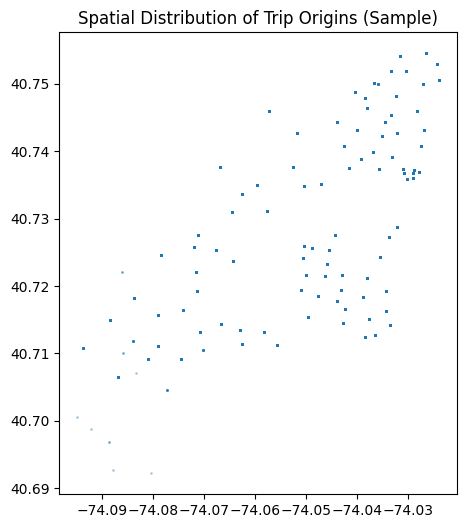

In [12]:
import matplotlib.pyplot as plt
gdf.sample(50000).plot(
    markersize=1,
    alpha=0.3,
    figsize=(6,6)
)

plt.title("Spatial Distribution of Trip Origins (Sample)")
plt.show()

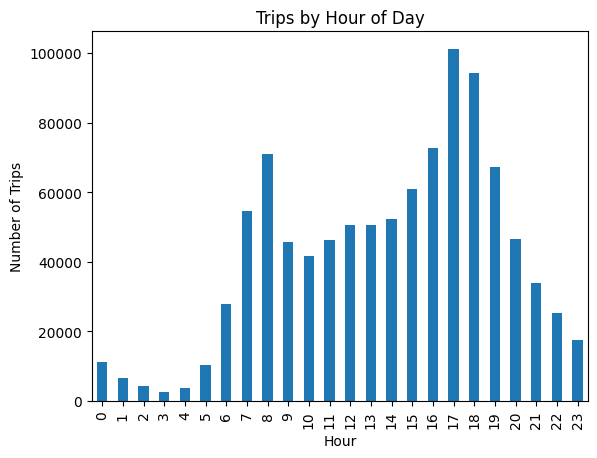

In [13]:
df["hour"] = df["started_at"].dt.hour

df.groupby("hour").size().plot(kind="bar")

plt.title("Trips by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Trips")
plt.show()

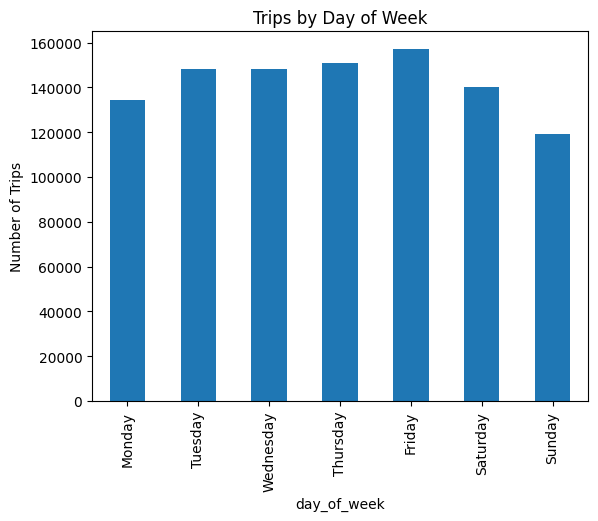

In [19]:
df["day_of_week"] = df["started_at"].dt.day_name()

df.groupby("day_of_week").size().reindex([
    "Monday","Tuesday","Wednesday","Thursday",
    "Friday","Saturday","Sunday"
]).plot(kind="bar")

plt.title("Trips by Day of Week")
plt.ylabel("Number of Trips")
plt.show()

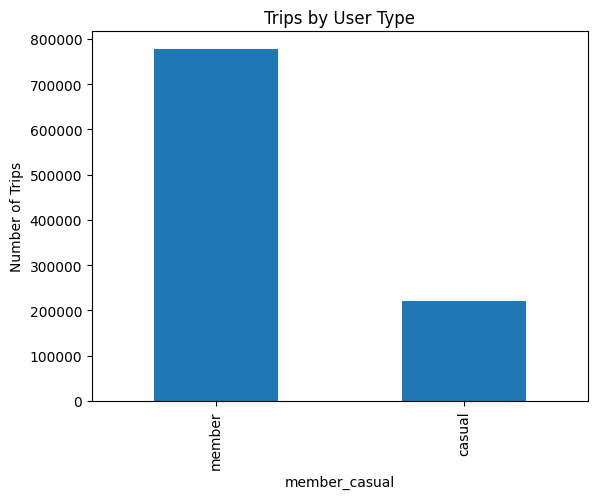

In [20]:
df["member_casual"].value_counts().plot(kind="bar")

plt.title("Trips by User Type")
plt.ylabel("Number of Trips")
plt.show()

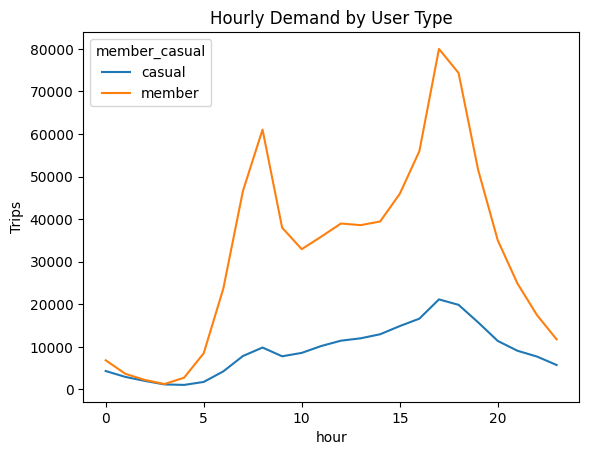

In [21]:
df.groupby(["hour","member_casual"]).size().unstack().plot()

plt.title("Hourly Demand by User Type")
plt.ylabel("Trips")
plt.show()

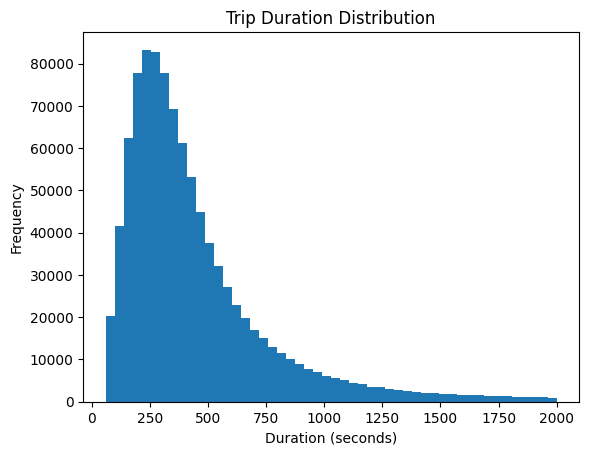

In [16]:
df[df["trip_duration_sec"] < 2000]["trip_duration_sec"].plot(kind="hist", bins=50)

plt.title("Trip Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.show()

In [15]:
summary = df[["trip_duration_sec", "distance_km", "speed_kmh"]].describe()
summary

,trip_duration_sec,distance_km,speed_kmh
count,998234.000000,998234.000000,998234.000000
mean,528.293681,1.220145,11.065621
std,655.805852,0.793755,4.711120
min,60.063000,0.000000,0.000000
25%,237.491000,0.685122,8.422577
50%,361.252500,1.049304,11.155574
75%,570.500000,1.571287,14.093303
max,14390.224000,25.931052,36.076492


## Key Observations

- The distribution of trip duration is right-skewed (mean > median), indicating a majority of short trips with a long recreational tail.
- Peak travel hours (8 AM and 5–6 PM) indicate commuter-oriented demand.
- Average cycling speed (~11 km/h) aligns with realistic urban cycling behavior.
- Weekday demand exceeds weekend demand, reinforcing the commuter-oriented nature of the system.
- Spatial clustering indicates concentration in high-density urban corridors.
- Members exhibit pronounced peak-hour patterns, whereas casual users show relatively smoother daytime usage, suggesting differing mobility purposes.
- The median trip duration (361 seconds) being lower than the mean (528 seconds) confirms the presence of a long-tail distribution.

In [17]:
final_columns = [
    "ride_id",
    "rideable_type",
    "started_at",
    "ended_at",
    "trip_duration_sec",
    "start_station_name",
    "start_station_id",
    "end_station_name",
    "end_station_id",
    "start_lat",
    "start_lng",
    "end_lat",
    "end_lng",
    "distance_km",
    "speed_kmh",
    "member_casual",
    "source_file"
]

df_final = df[final_columns].copy()

print("Final dataset shape:", df_final.shape)

Final dataset shape: (998234, 17)


In [18]:
output_path = "citi_bike_2025_cleaned_consolidated.csv"

df_final.to_csv(
    output_path,
    index=False
)

print("File saved successfully.")

File saved successfully.


## Consolidated Cleaned Dataset

After preprocessing and exploratory analysis, the cleaned dataset was exported as:

**citi_bike_2025_cleaned_consolidated.csv**

The final dataset includes:

- 998,234 valid trip records
- Computed trip duration (seconds)
- Haversine distance (km)
- Estimated cycling speed (km/h)
- All 12 months consolidated into one file

This dataset is now suitable for subsequent spatial aggregation, routing, and modelling tasks.